In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (confusion_matrix, classification_report,
                             accuracy_score, ConfusionMatrixDisplay)
import warnings
warnings.filterwarnings('ignore')
print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
import os
paths_to_try = [
    'Diabetes_prediction.csv',
    '../datasets/Diabetes_prediction.csv',
    'datasets/Diabetes_prediction.csv',
    '../Diabetes_prediction.csv'
]
df = None
for path in paths_to_try:
    if os.path.exists(path):
        df = pd.read_csv(path)
        print(f"Dataset loaded from: {path}")
        break
if df is None:
    raise FileNotFoundError("Could not find Diabetes_prediction.csv")
print(f"Shape: {df.shape}")
df.head()

Dataset loaded from: Diabetes_prediction.csv
Shape: (1000, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Diagnosis
0,2,115.863387,56.410731,24.336736,94.385783,26.455940,0.272682,20.100494,0
1,2,92.490122,70.615520,23.443591,138.652426,23.910167,0.665160,44.912281,0
2,1,88.141469,63.262618,23.404364,149.358082,21.948250,0.676022,48.247873,1
3,2,108.453101,67.793632,20.751580,108.751638,24.209304,0.289636,42.749868,0
4,1,127.849443,94.725685,22.603078,25.269987,32.997477,0.601315,32.797789,0


In [3]:
feature_cols = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness',
                'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']
X = df[feature_cols]
y = df['Diagnosis']

print("Target distribution:")
print(y.value_counts())
print(f"\nPositive class ratio: {y.mean():.3f}")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# MANDATORY: Feature scaling for KNN
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"\nTraining set size: {X_train.shape[0]}")
print(f"Test set size: {X_test.shape[0]}")
print("\nFeature scaling applied (StandardScaler)")
print(f"Before scaling - Glucose mean: {X_train['Glucose'].mean():.2f}")
print(f"After scaling  - Glucose mean: {X_train_scaled[:, 1].mean():.4f}")

Target distribution:
Diagnosis
0    694
1    306
Name: count, dtype: int64

Positive class ratio: 0.306

Training set size: 800
Test set size: 200

Feature scaling applied (StandardScaler)
Before scaling - Glucose mean: 98.76
After scaling  - Glucose mean: 0.0000


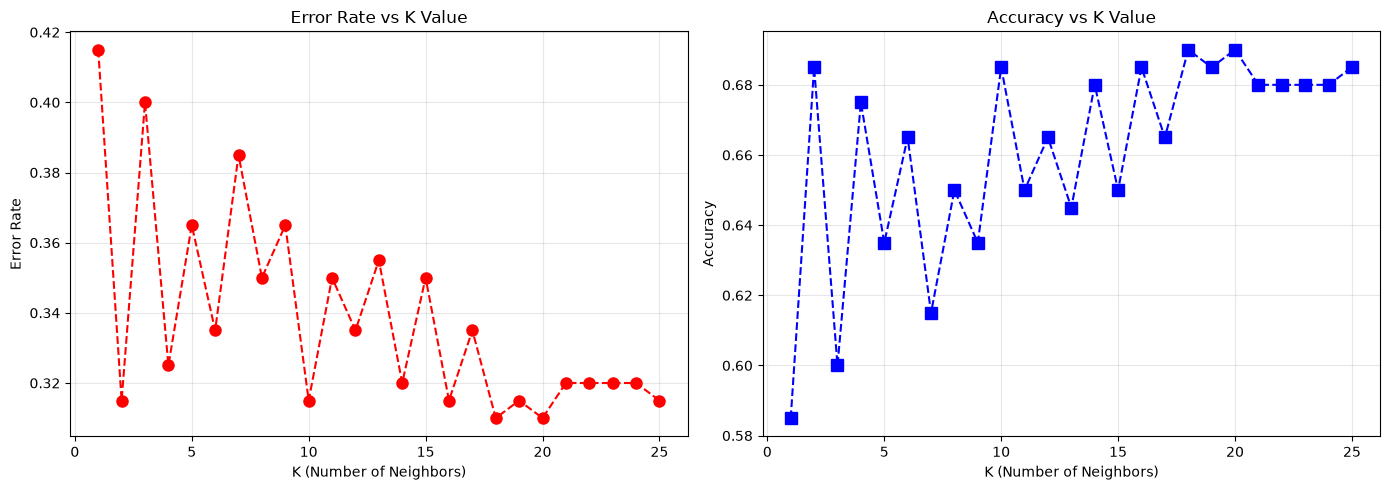

Optimal K: 18
Best Accuracy: 0.6900 (69.00%)


In [4]:
k_range = range(1, 26)
error_rates = []
accuracies = []

for k in k_range:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    pred = knn.predict(X_test_scaled)
    error_rates.append(1 - accuracy_score(y_test, pred))
    accuracies.append(accuracy_score(y_test, pred))

# Plot elbow curve
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(list(k_range), error_rates, color='red', marker='o', linestyle='dashed',
         markerfacecolor='red', markersize=8)
ax1.set_title('Error Rate vs K Value')
ax1.set_xlabel('K (Number of Neighbors)')
ax1.set_ylabel('Error Rate')
ax1.grid(True, alpha=0.3)

ax2.plot(list(k_range), accuracies, color='blue', marker='s', linestyle='dashed',
         markerfacecolor='blue', markersize=8)
ax2.set_title('Accuracy vs K Value')
ax2.set_xlabel('K (Number of Neighbors)')
ax2.set_ylabel('Accuracy')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

optimal_k = list(k_range)[accuracies.index(max(accuracies))]
print(f"Optimal K: {optimal_k}")
print(f"Best Accuracy: {max(accuracies):.4f} ({max(accuracies)*100:.2f}%)")

In [5]:
# Train final KNN with optimal K
knn_final = KNeighborsClassifier(n_neighbors=optimal_k)
knn_final.fit(X_train_scaled, y_train)
y_pred = knn_final.predict(X_test_scaled)

print("=" * 60)
print(f"FINAL KNN MODEL EVALUATION (K = {optimal_k})")
print("=" * 60)
print(f"\nAccuracy: {accuracy_score(y_test, y_pred):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['Non-Diabetic', 'Diabetic']))

FINAL KNN MODEL EVALUATION (K = 18)

Accuracy: 0.6900

Classification Report:
              precision    recall  f1-score   support

Non-Diabetic       0.69      0.99      0.82       139
    Diabetic       0.00      0.00      0.00        61

    accuracy                           0.69       200
   macro avg       0.35      0.50      0.41       200
weighted avg       0.48      0.69      0.57       200



<Figure size 700x500 with 0 Axes>

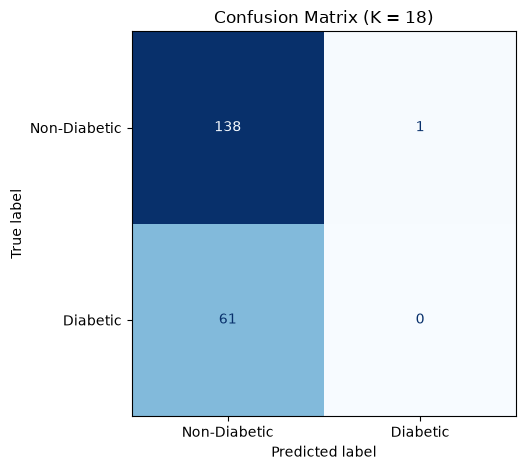


Comparison of different K values:
---------------------------------------------
    K |   Accuracy |                Notes
---------------------------------------------
    1 |     0.5850 |                     
    3 |     0.6000 |                     
    5 |     0.6350 |                     
    7 |     0.6150 |                     
    9 |     0.6350 |                     
   18 |     0.6900 |          <-- Optimal


In [6]:
# Confusion Matrix
plt.figure(figsize=(7, 5))
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Non-Diabetic', 'Diabetic'])
disp.plot(colorbar=False, cmap='Blues')
plt.title(f'Confusion Matrix (K = {optimal_k})')
plt.tight_layout()
plt.show()

# Compare K=1,3,5,7,optimal_k
print("\nComparison of different K values:")
print("-" * 45)
print(f"{'K':>5} | {'Accuracy':>10} | {'Notes':>20}")
print("-" * 45)
for k in [1, 3, 5, 7, 9, optimal_k]:
    knn_temp = KNeighborsClassifier(n_neighbors=k)
    knn_temp.fit(X_train_scaled, y_train)
    acc = accuracy_score(y_test, knn_temp.predict(X_test_scaled))
    note = "<-- Optimal" if k == optimal_k else ""
    print(f"{k:>5} | {acc:>10.4f} | {note:>20}")